# Does Eternal's ten minute kitchen undercut its own marketplace?

Eternal Ltd runs two food delivery businesses that reach the same customer in the same city.

* **Zomato** is a marketplace. Restaurants cook, Eternal takes a commission.
* **Bistro** is an owned kitchen inside the Blinkit app. Eternal cooks, and keeps the whole order value less what it costs to produce.

The company tells investors these do not compete. Its July 2026 shareholder letter calls Bistro
*"a different segment, a different occasion, and a genuinely new market"* aimed at
*"INR 50-150 price points"*.

That is a claim about a price distribution, and a price distribution can be measured.

This notebook tests it on primary data. 355 screenshots were collected by hand from three apps in
Delhi on 1 September 2026, then matched dish by dish. The question is simple to state: **for a dish
both services sell, is the owned kitchen reliably cheaper?**

If the answer is no, the segmentation claim survives. If the answer is yes, the two are selling the
same product at two prices, which is competition rather than segmentation.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, menu, offers, viz
from src import estimate as E
from src import unit_economics as U

viz.apply_style()
pd.set_option("display.width", 200)

## 1. What is in the data

One row is one restaurant's quote for one dish on one platform. Bistro contributes one quote per
dish because it is a single kitchen. The marketplaces contribute many, because many restaurants sell
the same dish.

In [2]:
panel = menu.load_menu_prices(config.MENU_PRICES_LONG)

print(f"{len(panel)} quotes, {panel.matched_id.nunique()} dishes")
print(panel.platform.value_counts().to_string())
panel[["platform", "dish_name_raw", "restaurant_name", "list_price", "units", "section"]].head(8)

225 quotes, 28 dishes
platform
Swiggy    108
Zomato     89
Bistro     28


,platform,dish_name_raw,restaurant_name,list_price,units,section
0,Bistro,Chicken Dum Biryani (Boneless),Bistro,259.0,1.0,Meals
1,Bistro,Paneer Makhani Biryani,Bistro,239.0,1.0,Meals
2,Bistro,Chicken Keema Pav,Bistro,189.0,1.0,Meals
3,Bistro,Rajma Rice,Bistro,159.0,1.0,Meals
4,Bistro,Chole Kulche,Bistro,149.0,1.0,Meals
5,Bistro,Yellow Dal Tadka & Rice,Bistro,149.0,1.0,Meals
6,Bistro,Crispy Fried Chicken,Bistro,249.0,2.0,Quick Bites
7,Bistro,Crispy Chicken Popcorn,Bistro,179.0,1.0,Quick Bites


Every screenshot is accounted for. The table below traces the whole collection to the analysis
sample, and each row is a rule applied rather than a judgement recorded afterwards.

The largest loss is prices that could not be read because a scrolling screenshot cut the card. The
second largest is a manual review that removed listings which passed every automated check and were
still the wrong product: half portions, mini bowls, sweet boxes and two dish combos.

In [3]:
flow = pd.read_csv(config.PROCESSED / "menu_exclusion_flow.csv")
flow["lost"] = flow.rows_remaining.diff().fillna(0).astype(int)
flow[["stage", "rows_remaining", "lost", "reason_dropped"]]

,stage,rows_remaining,lost,reason_dropped
0,dish rows transcribed,794,0,NaN
1,price readable,594,-200,unreadable price
2,restaurant identifiable,481,-113,header off-screen
3,card fully in frame,370,-111,clipped by the scroll edge
4,under the matching section,344,-26,listed under Recommended/Most ordered
5,search not a collapsed query,314,-30,Tea/Chai/Chaat each cover 3 Bistro dishes
6,search term maps to a Bistro dish,309,-5,unmapped or blank
7,passes CORE and FORM veto,254,-55,"wrong dish, or a bulk/box/combo listing"
8,passes the manual format review,204,-50,"wrong product format: half, mini, bulk or a tw..."
9,quantity resolvable,197,-7,"volume basis with no stated volume, never defa..."


## 2. The two price distributions

Before any modelling, this is what the raw prices look like.

Two things stand out. The distributions overlap heavily, which is what makes a comparison possible.
And Bistro stops. Its dearest item anywhere on the menu is far below where the marketplace
continues, so any order above that ceiling is out of reach no matter how cheap Bistro is below it.

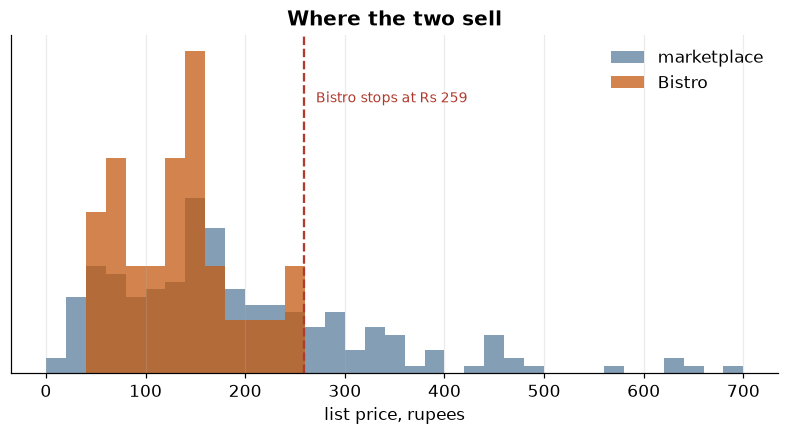

Bistro      Rs 49 to Rs 259, median Rs 139
marketplace Rs 19 to Rs 683, median Rs 160


In [4]:
b = panel[panel.platform == "Bistro"].list_price
m = panel[panel.platform != "Bistro"].list_price

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 700, 36)
ax.hist(m, bins=bins, alpha=.55, density=True, color=viz.PALETTE["fd"], label="marketplace")
ax.hist(b, bins=bins, alpha=.75, density=True, color=viz.PALETTE["qc"], label="Bistro")
ax.axvline(b.max(), color=viz.PALETTE["negative"], ls="--")
ax.text(b.max() + 12, ax.get_ylim()[1] * .8, f"Bistro stops at Rs {b.max():.0f}",
        color=viz.PALETTE["negative"], fontsize=9)
ax.set_xlabel("list price, rupees"); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("Where the two sell")
plt.show()

print(f"Bistro      Rs {b.min():.0f} to Rs {b.max():.0f}, median Rs {b.median():.0f}")
print(f"marketplace Rs {m.min():.0f} to Rs {m.max():.0f}, median Rs {m.median():.0f}")

## 3. One measurement problem that can flip the sign

Platforms sell the same dish in different quantities. Bistro sells Aloo Pyaaz Paratha as two pieces.
Several restaurants sell one piece. On the menu Bistro looks dearer. Per piece it is much cheaper.

The obvious fix is to divide price by quantity. The fix creates a worse problem, because most
listings never state a quantity at all.

In [5]:
paratha = panel[panel.matched_id == 59][
    ["platform", "restaurant_name", "dish_name_raw", "list_price", "units", "unit_price"]]
paratha.sort_values("unit_price")

,platform,restaurant_name,dish_name_raw,list_price,units,unit_price
210,Swiggy,Amritsariya,Aloo Pyaaz Parantha [single],45.0,1.0,45.0
213,Swiggy,Pind Balluchi,Aloo Pyaz Paratha,79.0,1.0,79.0
22,Bistro,Bistro,Aloo Pyaaz Paratha,159.0,2.0,79.5
212,Swiggy,Bengal Sweet Corner,ALOO PYAZ PARANTHA WITH,119.0,1.0,119.0
211,Swiggy,Chaayos Chai+Snacks=Relax,Aloo Pyaaz Paratha (1 pc),139.0,1.0,139.0
95,Zomato,Haldiram's,Aloo Pyaz Parantha With Curd - 1 pc,140.0,1.0,140.0
214,Swiggy,Haldiram's,Aloo Pyaz Parantha With Curd - 1 pc,140.0,1.0,140.0
93,Zomato,Chaayos Chai+Sna…,Aloo Pyaaz Paratha (1 pc),155.0,1.0,155.0
96,Zomato,Pind Balluchi,Tandoori Aloo Pyaaz Paratha,220.0,1.0,220.0
94,Zomato,Wagh Bakri Tea Lounge,Loaded Aloo Pyaaz Paratha,249.0,1.0,249.0


The relationship between the two ways of measuring is an identity, not a second estimate. Because

$$\log\!\left(\frac{p}{u}\right) = \log p - \log u$$

running the model on unit price is the same as running it on list price and subtracting the
within dish gap in log quantity. Call that gap $\Delta$. Then

$$\beta_{\text{unit}} = \beta_{\text{list}} - \Delta$$

So normalising by quantity does not discover anything. It subtracts a number, and that number is
chosen by assumption.

In [6]:
unit, _ = E.identified_dishes(E.prepare(panel, outcome="unit_price"))
bridge = E.delta_bridge(unit)

for k, v in bridge.items():
    print(f"  {k:<14} {v:+.4f}")
print("\nThe identity residual is zero to machine precision, so the bridge is arithmetic.")

  beta_list      -0.2119
  beta_unit      -0.3185
  delta          +0.1066
  delta_se       +0.0828
  identity_gap   -0.0000

The identity residual is zero to machine precision, so the bridge is arithmetic.


Two thirds of marketplace listings state no portion size. The pipeline reads silence as one serving,
which is the natural default and also the reading most favourable to the hypothesis.

The honest response is to refit under every defensible alternative and see whether the answer holds.

In [7]:
qs = E.quantity_sensitivity(panel)
qs.style.format({"beta": "{:+.3f}", "se": "{:.3f}", "p": "{:.3f}"})

,treatment,assumption,beta,se,p,n
0,unstated read as one serving,favours,-0.318,0.097,0.001,215
1,imputed from the dish median,against,-0.151,0.093,0.103,215
2,every unstated piece listing is 2 pieces,against,-0.237,0.099,0.017,215
3,every unstated piece listing is 3 pieces,against,-0.189,0.105,0.071,215
4,"list price, quantity never used",none,-0.206,0.089,0.021,225


The sign never changes. The significance does. Under the dish median rule the per unit coefficient
is no longer significant at five per cent.

Neither end of that range is the truth. Reading silence as one serving under corrects, because some
silent listings really are multi packs. Reading it as the dish median over corrects, because a
listing states its count precisely when it is a multi pack and stays quiet when it is a single
serving.

**So list price becomes the outcome.** It needs no quantity information at all and its estimate sits
inside the range the per unit specification spans. That decision is taken by a diagnostic in the next
section, not by preference.

## 4. The model is chosen by its diagnostics

The usual order of work is to fit a preferred model and report diagnostics beside it. Used that way
a diagnostic can only confirm or embarrass a decision already taken.

This study reverses the order. Ten gates run in sequence. Each one reads a statistic and hands the
next a decision, and the specification is whatever comes out of the last gate. Thresholds are fixed
in code before any gate runs, so no test gets a cutoff chosen after its answer was known.

In [8]:
trail, chosen = E.run_cascade(panel, n_boot=2999)

for _, g in trail.iterrows():
    print(f"GATE {g.step}. {g.question}")
    print(f"   reads     {g.verdict}")
    print(f"   therefore {g.consequence}\n")

GATE 1. Is the outcome linear in levels or in logs?
   reads     skew falls from 0.96 in levels to 0.18 in logs; RESET p = 0.402
   therefore log price is the dependent variable, and beta reads as a percentage gap

GATE 2. Do dishes differ enough to need their own intercepts?
   reads     F = 15.4, p = <0.001; beta moves from -0.303 pooled to -0.324 with dish effects
   therefore item fixed effects, Model 2. The gap between the two betas is the assortment composition effect, and it is reported rather than hidden

GATE 3. Does every dish actually identify the contrast?
   reads     27 dishes identify beta, 0 dropped
   therefore the estimation sample is 215 rows over 27 dishes

GATE 4. Is the error variance constant?
   reads     Breusch-Pagan p = <0.001; heteroscedastic. White is rank deficient in a fixed effects design and is not reported
   therefore robust standard errors, which the clustered errors in gate 5 already are

GATE 5. Are errors correlated within a dish?
   reads     ICC

Four gates are worth pausing on.

**Gate 2** rejected pooling. Dishes differ so much that a model without dish effects is
misspecified, so the comparison has to be within a dish.

**Gate 6** made the bootstrap compulsory. The study has 28 clusters, well below the range where the
asymptotic cluster robust variance behaves. The wild cluster bootstrap is the inference here, not a
robustness extra.

**Gate 9** changed the dependent variable, for the quantity reason in section 3.

**Gate 10** put the rank test first in the results, because it assumes the least.

## 5. Does the gap exist? The answer that assumes almost nothing

The first question is not how large the gap is. It is whether there is one.

For each dish, Bistro's price is placed inside the distribution of that dish's marketplace quotes and
its percentile rank recorded. Under the null that Bistro prices like any other seller, the mean rank
is 0.50.

This uses only the ordering of prices within a dish. No quantity conversion, no functional form and
no distributional assumption can move it.

In [9]:
ranks = menu.bistro_percentile_rank(panel, price_col="list_price")
rt = E.rank_test(ranks.bistro_rank)

for k, v in rt.items():
    print(f"  {k:<16} {v:.4f}" if isinstance(v, float) else f"  {k:<16} {v}")

  n_dishes         28
  mean_rank        0.2906
  median_rank      0.1534
  n_below_half     19
  wilcoxon_stat    48.0000
  wilcoxon_p       0.0019
  sign_p           0.0872


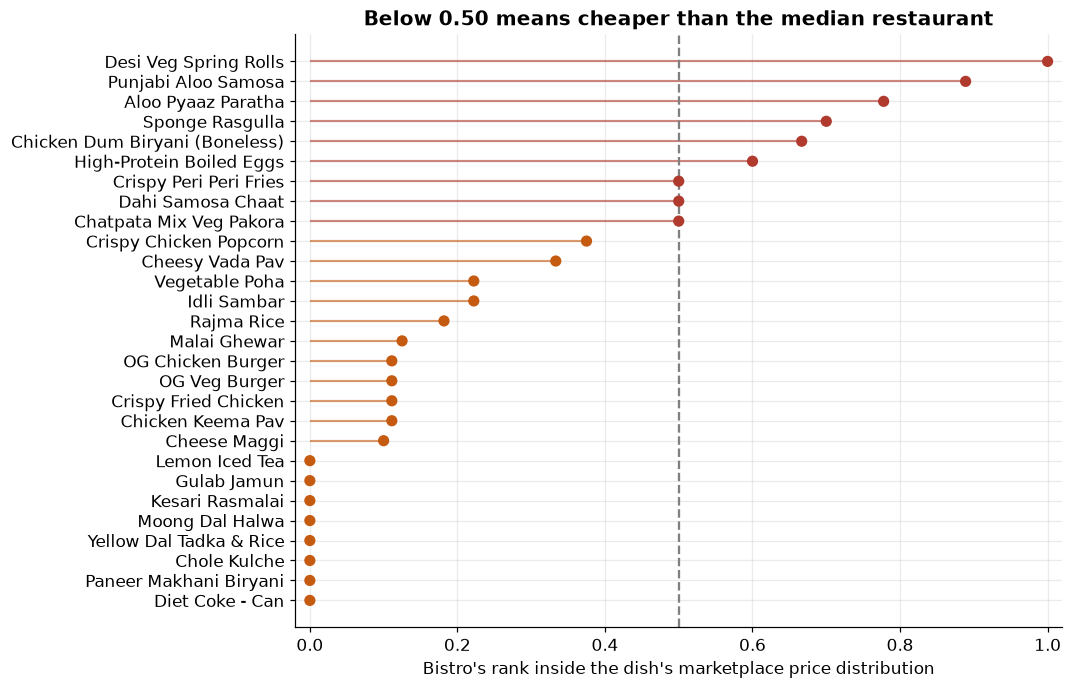

In [10]:
names = panel[panel.platform == "Bistro"].set_index("matched_id").dish_name_raw
r = ranks.assign(name=ranks.matched_id.map(names)).sort_values("bistro_rank")
cols = [viz.PALETTE["qc"] if v < .5 else viz.PALETTE["negative"] for v in r.bistro_rank]

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(r.name, 0, r.bistro_rank, color=cols, lw=1.4, alpha=.6)
ax.scatter(r.bistro_rank, r.name, color=cols, s=40, zorder=3)
ax.axvline(.5, color="grey", ls="--")
ax.set_xlabel("Bistro's rank inside the dish's marketplace price distribution")
ax.set_xlim(-.02, 1.02)
ax.set_title("Below 0.50 means cheaper than the median restaurant")
plt.show()

The mean rank is well below 0.50 and the Wilcoxon test rejects clearly.

One detail in that output is a finding rather than a blemish. The sign test and the Wilcoxon test
disagree, because they use different information. The sign test counts how many dishes fall below the
median and ignores by how much. The Wilcoxon uses the size of the gap too.

The gap is lopsided. Where Bistro undercuts, it undercuts by a lot. Where Bistro is dearer, it is
barely dearer. That pattern moves a Wilcoxon statistic and leaves a sign test unmoved.

In [11]:
cheap, dear = ranks[ranks.bistro_rank < .5], ranks[ranks.bistro_rank >= .5]
gap = lambda g: np.exp(np.log(g.bistro_price / g.mkt_median).median()) - 1

print(f"cheaper in {len(cheap)} dishes, by a median of {gap(cheap):.0%}")
print(f"dearer  in {len(dear)} dishes, by a median of {gap(dear):+.0%}")
print(f"\nwithin a dish the dearest restaurant charges "
      f"{(ranks.mkt_max / ranks.mkt_min).median():.1f}x the cheapest")

cheaper in 19 dishes, by a median of -31%
dearer  in 9 dishes, by a median of +9%

within a dish the dearest restaurant charges 2.9x the cheapest


That last number matters for how the headline is read. Bistro is not undercutting a market price,
because there is no single market price. It sits low inside a wide distribution.

It also explains why holding the dish constant matters so much. With this much spread between
restaurants selling the same dish, a comparison that ignored the dish would be measuring assortment
rather than pricing.

## 6. How large is the gap?

The main specification gives every dish its own intercept, so the coefficient is identified only from
variation within a dish across platforms. It compares the same paratha against the same paratha and
never a paratha against a biryani.

$$\log p_{ipr} = \alpha_i + \beta\,\text{Owned}_p + \varepsilon_{ipr}$$

Errors are clustered by dish, and each row is weighted by the inverse of the number of rows in its
dish and platform cell so that screenshot count cannot drive the estimate.

In [12]:
c, boot = chosen["coef"], chosen["bootstrap"]

print(f"beta = {c['beta']:+.4f}   a matched dish costs {abs(c['pct']):.1%} less on Bistro")
print(f"  cluster robust SE     {c['se']:.4f}")
print(f"  95% interval          {c['ci_lo']:+.3f} to {c['ci_hi']:+.3f}")
print(f"  asymptotic p          {c['p']:.4f}")
print(f"  wild bootstrap p      {boot['p_boot']:.4f}  over {boot['n_boot']} replications")
print(f"  n = {c['n']} quotes over {chosen['n_clusters']} dishes")

beta = -0.2059   a matched dish costs 18.6% less on Bistro
  cluster robust SE     0.0889
  95% interval          -0.380 to -0.032
  asymptotic p          0.0205
  wild bootstrap p      0.0243  over 2999 replications
  n = 225 quotes over 28 dishes


The two p values agree, which is the useful outcome. Had they diverged the bootstrap would have
governed, because 28 clusters is too few for the asymptotic formula to be trusted alone.

Next, whether the number survives every reasonable way of cutting the sample.

In [13]:
d = chosen["sample"]
eff, _ = E.identified_dishes(E.prepare(panel, outcome="effective_price", drop_unreliable=False))
stated, _ = E.identified_dishes(d[d.qty_source.isin(("name", "description"))])

specs = {
    "pooled OLS, no dish effects":   E.coef(E.fit_pooled(d)),
    "main, item fixed effects":      c,
    "per unit price":                E.coef(E.fit_item_fe(unit)),
    "after item discounts":          E.coef(E.fit_item_fe(eff)),
    "unweighted":                    E.coef(E.fit_item_fe(d, weighted=False)),
    "sponsored rows dropped":        E.coef(E.fit_item_fe(E.identified_dishes(d[~d.is_sponsored.fillna(False)])[0])),
    "best match grade only":         E.coef(E.fit_item_fe(E.identified_dishes(d[d.match_grade == "A_exact"])[0])),
    "quantity stated, not assumed":  E.coef(E.fit_item_fe(stated)),
}
for plat in ("Zomato", "Swiggy"):
    sub, _ = E.identified_dishes(d[d.platform.isin(["Bistro", plat])])
    specs[f"against {plat} only"] = E.coef(E.fit_item_fe(sub))

pd.DataFrame(specs).T[["beta", "se", "p", "n"]].style.format(
    {"beta": "{:+.3f}", "se": "{:.3f}", "p": "{:.3f}", "n": "{:.0f}"})

,beta,se,p,n
"pooled OLS, no dish effects",-0.202,0.088,0.022,225
"main, item fixed effects",-0.206,0.089,0.021,225
per unit price,-0.318,0.097,0.001,215
after item discounts,-0.206,0.089,0.021,225
unweighted,-0.205,0.086,0.017,225
sponsored rows dropped,-0.214,0.095,0.025,177
best match grade only,-0.224,0.180,0.213,45
"quantity stated, not assumed",-0.211,0.175,0.230,47
against Zomato only,-0.276,0.105,0.009,113
against Swiggy only,-0.158,0.109,0.146,133


The estimate is stable. Two cuts lose significance and the reason is sample size rather than sign:
they hold about 45 rows each, so the standard error roughly doubles while the coefficient barely
moves. A stable point estimate with a widening interval is what a shrinking sample should look like.

Two further checks the design demands.

In [14]:
loo = chosen["loo"]
print(f"leave one dish out: beta ranges {loo.beta.min():+.3f} to {loo.beta.max():+.3f}, "
      f"sign flips {int((np.sign(loo.beta) != np.sign(c['beta'])).sum())} times")

import src.run_menu_study as R
pc = R.platform_contrast(d)
print(f"\nSwiggy against Zomato within a dish: {pc['diff']:+.3f} "
      f"(se {pc['se']:.3f}, p {pc['p']:.3f})")
print("The two marketplaces were captured by different methods. This tests whether that matters.")

leave one dish out: beta ranges -0.245 to -0.166, sign flips 0 times

Swiggy against Zomato within a dish: -0.093 (se 0.091, p 0.307)
The two marketplaces were captured by different methods. This tests whether that matters.


No single dish carries the result, and the two marketplaces do not differ from each other. The second
check matters because Zomato was captured by tapping into each restaurant while Swiggy was captured
from a results list, and those select different restaurants into the top five.

## 7. What the customer actually pays

The menu price is not the price. Three things sit between the two: fees, basket size and coupons.

Bistro charges no delivery fee and a flat three rupees. The marketplaces add delivery, platform and
packaging charges on every order.

In [15]:
fees = pd.read_csv(config.CHECKOUT_FEES).drop_duplicates("platform", keep="first").set_index("platform")
fees[["item_total", "delivery_fee", "platform_fee", "convenience_fee",
      "gst_and_other", "grand_total", "wedge_pct"]]

,item_total,delivery_fee,platform_fee,convenience_fee,gst_and_other,grand_total,wedge_pct
platform,,,,,,,
Bistro,79,0,NaN,3.0,NaN,82,0.038
Zomato,149,59,14.9,NaN,21.72,264,0.772
Swiggy,184,48,NaN,NaN,74.82,292,0.587


Those wedges are computed on a single item order, and that flatters Bistro. A real marketplace order
is larger, and a fixed delivery fee spreads over a bigger basket.

Fees split in two. Delivery and platform charges are fixed per order. Packaging and tax scale with
order value. So the wedge on a basket of size $x$ is

$$w(x) = \frac{F}{x} + v$$

which falls as the basket grows but never below $v$.

In [16]:
curve = E.fee_wedge_curve(c["beta"], fees)
curve[curve.platform == "Zomato"][["basket", "wedge", "owned_wedge",
                                   "owned_pays", "marketplace_pays", "delivered_gap"]].style.format(
    {"wedge": "{:.0%}", "owned_wedge": "{:.1%}", "owned_pays": "Rs {:.0f}",
     "marketplace_pays": "Rs {:.0f}", "delivered_gap": "{:+.0%}"})

,basket,wedge,owned_wedge,owned_pays,marketplace_pays,delivered_gap
0,149,77%,2.0%,Rs 124,Rs 264,-53%
1,200,65%,1.5%,Rs 165,Rs 329,-50%
2,300,52%,1.0%,Rs 247,Rs 457,-46%
3,400,46%,0.8%,Rs 328,Rs 584,-44%
4,500,42%,0.6%,Rs 409,Rs 712,-42%
5,700,38%,0.4%,Rs 572,Rs 967,-41%


The gap narrows as the basket grows and does not close, because the proportional part of the fee
stack does not shrink.

Everything so far still ignores coupons, and a customer does not. The offer text captured with every
restaurant is parsed into a rule and evaluated at each basket size.

Most coupons are capped, of the form *70% off upto Rs 140*, so they shrink as a share of a larger
order. Many carry a threshold, so at a small basket they do not fire at all.

In [17]:
off = offers.parse_all(pd.read_csv(config.MARKETPLACE_RAW))
dcurve = offers.discount_curve(off, E.BASKET_GRID)

print(off.groupby("platform").rule.apply(lambda s: f"{s.notna().sum()} of {len(s)} parse to a basket coupon").to_string())
dcurve[dcurve.platform == "Zomato"][["basket", "share_firing", "typical_pct", "best_pct"]].style.format(
    {"share_firing": "{:.0%}", "typical_pct": "{:.0%}", "best_pct": "{:.0%}"})

platform
Swiggy    85 of 129 parse to a basket coupon
Zomato     57 of 97 parse to a basket coupon


,basket,share_firing,typical_pct,best_pct
6,149,16%,54%,67%
7,200,37%,40%,70%
8,300,43%,27%,47%
9,400,45%,20%,38%
10,500,52%,16%,30%
11,700,58%,11%,21%


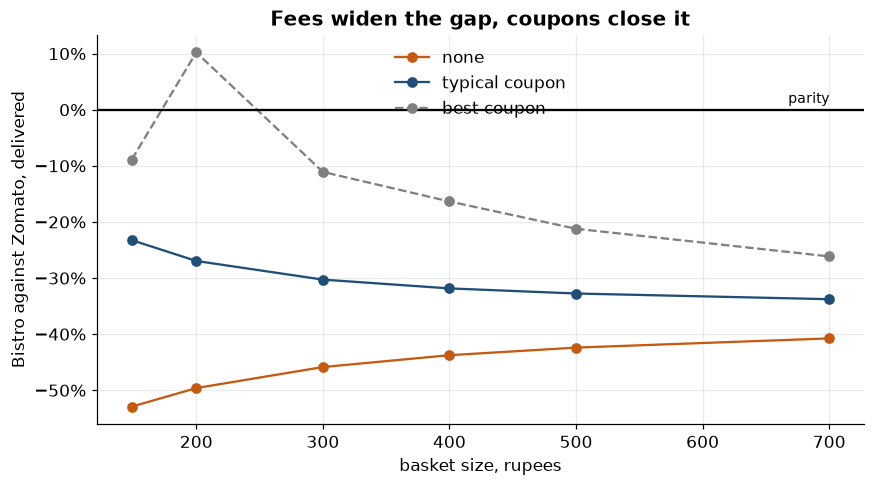

coupon,none,typical coupon,best coupon
basket,,,
149,-53%,-23%,-9%
200,-50%,-27%,+10%
300,-46%,-30%,-11%
400,-44%,-32%,-16%
500,-42%,-33%,-21%
700,-41%,-34%,-26%


In [18]:
checkout = E.checkout_comparison(c["beta"], fees, dcurve)
z = checkout[checkout.platform == "Zomato"]

fig, ax = plt.subplots(figsize=(9, 4.6))
for lab, col, ls in [("none", viz.PALETTE["qc"], "-"),
                     ("typical coupon", viz.PALETTE["fd"], "-"),
                     ("best coupon", "grey", "--")]:
    g = z[z.coupon == lab].sort_values("basket")
    ax.plot(g.basket, g.gap, marker="o", color=col, ls=ls, label=lab)
ax.axhline(0, color="black")
ax.text(z.basket.max(), .012, "parity", ha="right", fontsize=9)
viz.pct_axis(ax)
ax.set_xlabel("basket size, rupees"); ax.set_ylabel("Bistro against Zomato, delivered")
ax.legend(frameon=False); ax.set_title("Fees widen the gap, coupons close it")
plt.show()

z.pivot(index="basket", columns="coupon", values="gap")[
    ["none", "typical coupon", "best coupon"]].style.format("{:+.0%}")

This is the honest end of the study and it is a weaker claim than the fee comparison alone.

* **Without a coupon** Bistro is roughly half the price.
* **With the coupon a typical restaurant offers** the gap falls to about a third.
* **With the single best coupon on the platform** the gap can close entirely, and at one basket size
  Bistro is dearer.

The last row needs a caveat. The best coupon is a maximum over roughly ninety restaurants, and taking
it means ordering from whichever restaurant runs it rather than the one selling the dish that was
wanted. It bounds what a determined customer could reach, not what a typical one gets.

The correction runs both ways. Bistro discounts too. One of its two captured checkouts shows a basket
struck from Rs 439 to Rs 239, and assuming it never discounts would be the same error in reverse.

## 8. So is this cannibalisation?

Here the study has to be honest about a limit built into its own design.

The sampling frame started from Bistro's menu, and Zomato was searched only for dishes Bistro already
sells. **The frame is the overlap.** The study measures the price gap where the two compete. It cannot
measure how much of the marketplace they compete for.

What the data does say points to partial rather than total substitution.

In [19]:
mkt = panel[panel.platform != "Bistro"]
print(f"Bistro's ceiling                          Rs {b.max():.0f}")
print(f"marketplace quotes reach                  Rs {mkt.list_price.max():.0f}, and the full catalogue goes further")
print(f"restaurants surfaced by {panel.matched_id.nunique()} dish searches   {mkt.restaurant_name.nunique()}")
print(f"Bistro's whole menu                       {len(pd.read_csv(config.BISTRO_MENU))} items")
print(f"\nmarketplace quotes cheaper than Bistro    {ranks.bistro_rank.mean():.0%} on average")
print(f"dishes where some restaurant undercuts    {(ranks.bistro_price > ranks.mkt_min).sum()} of {len(ranks)}")

Bistro's ceiling                          Rs 259
marketplace quotes reach                  Rs 683, and the full catalogue goes further
restaurants surfaced by 28 dish searches   117
Bistro's whole menu                       87 items

marketplace quotes cheaper than Bistro    29% on average
dishes where some restaurant undercuts    20 of 28


Partial sounds reassuring. The economics says it need not be.

Write $\alpha$ for the share of Bistro volume that would otherwise have been Zomato volume, $c_B$ and
$c_Z$ for the two contribution margins, and $\rho$ for the share Eternal would have kept anyway. One
rupee of Bistro order value adds

$$\Delta\Pi = c_B - \alpha\,\rho\,c_Z$$

Setting that to zero gives the cannibalisation rate at which Bistro stops adding anything:

$$\alpha^{*} = \frac{c_B}{\rho\,c_Z}$$

Zomato's contribution margin is disclosed. Bistro's is not, so the answer is conditional.

Zomato food delivery contribution margin: 10.19% of net order value



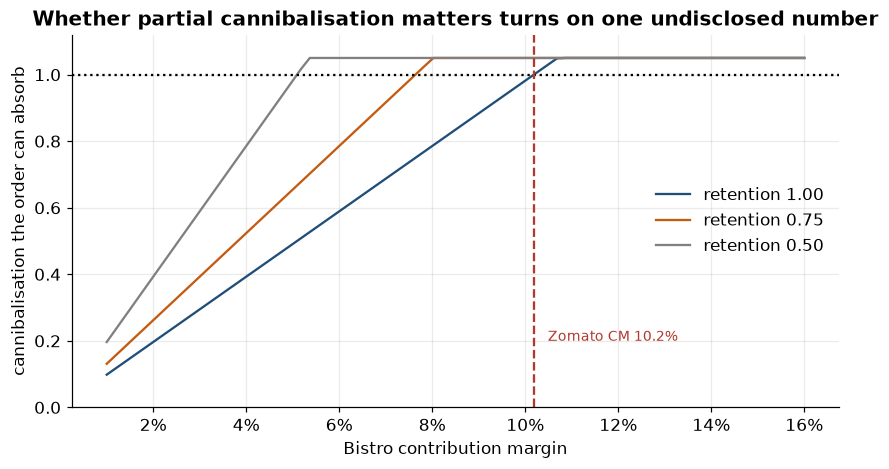

In [20]:
cmz = float(U.cm_zomato_from_contribution(pd.read_csv(config.PANEL), basis=1.0)
            .dropna(subset=["cm_zomato"]).cm_zomato.iloc[-1])
print(f"Zomato food delivery contribution margin: {cmz:.2%} of net order value\n")

grid = np.linspace(.01, .16, 80)
fig, ax = plt.subplots(figsize=(9, 4.4))
for ret, col in zip((1.0, .75, .5), [viz.PALETTE["fd"], viz.PALETTE["qc"], "grey"]):
    ax.plot(grid, [min(U.switching_value(x, cmz, ret), 1.05) for x in grid],
            color=col, label=f"retention {ret:.2f}")
ax.axhline(1, color="black", ls=":")
ax.axvline(cmz, color=viz.PALETTE["negative"], ls="--")
ax.text(cmz + .003, .2, f"Zomato CM {cmz:.1%}", color=viz.PALETTE["negative"], fontsize=9)
viz.pct_axis(ax, "both")
ax.set_xlabel("Bistro contribution margin"); ax.set_ylabel("cannibalisation the order can absorb")
ax.set_ylim(0, 1.12); ax.legend(frameon=False)
ax.set_title("Whether partial cannibalisation matters turns on one undisclosed number")
plt.show()

The whole question collapses to one comparison.

If Bistro's contribution margin beats Zomato's, no cannibalisation rate makes a Bistro order destroy
value, and whether substitution is partial or total stops mattering.

If Bistro's margin is below Zomato's, the threshold binds and how partial the cannibalisation is
becomes the entire argument. At a five per cent Bistro margin the threshold is about a half.

Eternal does not publish that number.

## 9. What this study found

**On the menu, the same dish is cheaper on Bistro.** The coefficient is negative and significant
under a bootstrap that does not rely on the small cluster count. A rank test that assumes almost
nothing agrees with it.

**At checkout the gap is larger but softer than it first looks.** Fees widen it to roughly a half on
a small order. A bigger basket spreads the fixed fees. A typical restaurant coupon pulls it to about
a third. The best coupon on the platform can close it.

**The specification was derived, not chosen.** Ten diagnostic gates decided the functional form, the
estimator, the error structure, the inference procedure and the dependent variable. Two of them
changed the answer rather than confirming it.

**The segmentation claim fails on price, inside the overlap.** Where the two services sell the same
dish, they sell the same product at two prices. That is competition.

**What the study cannot settle** is how large the overlap is. The frame is Bistro's menu, so the
reach of the substitution sits outside its scope by construction.

### What would weaken these findings

Two assumptions push the estimate toward the result and neither can be removed with this data.
Marketplace coupons are excluded from the coefficient, because an offer that depends on the whole
basket cannot be attached to one dish. And Bistro picks its own menu, so the estimate is the gap on
Bistro's chosen assortment rather than on food delivery in general.

The narrower limits: one city, one day, one collector, one owned kitchen operator, and matching that
rests on human judgement. Basket sizes are not disclosed by the company, which is why the checkout
comparison is reported across a grid rather than at a point.

---

**Reproducing this.** The panel is rebuilt from the raw transcription with
`python src/build_menu_panel.py`, and every table and figure in the paper with
`python src/run_menu_study.py`. The test suite covers the estimator, the quantity rules, the coupon
parser and the identities used above.